# Opening outcomes for training planning
## C1 tracking reconstruction

**Group 03:** Javier Alcaíno, Lucas Riquelme and Renato Varela. **Version:** 21 October 2026.

This notebook establishes the C1 baseline for the newly selected chess project.
It is a tracking reconstruction following the school-audit topic change, not a
claim that the original W1/C1 submission already used chess. The earlier project
remains preserved in its existing folder/repository. No C1 instructor feedback
was available at preparation time. Individual contributions and reflections
are not invented; the members must confirm them before any assessed reuse.

**Purpose:** help a proposed club training coordinator prioritise opening review
using exposure and color-specific points across rating bands, with blitz and rapid
analysed separately. The evidence is observational and bounded to the source windows.

## Seven-step decision map


| Step | Definition for this case |
|---|---|
| Decision | A proposed club training coordinator allocates opening-review sessions by speed, player level and color. No external stakeholder validation is claimed. |
| Success criteria | Provide traceable review priorities with adequate support. Actual learning gains or better future results would need intervention/follow-up data that are absent here. |
| Business question | How do opening-family exposure and observed points differ across rating bands, colors and blitz/rapid, and what can be predicted from a fixed opening checkpoint? |
| Business process | Choose a training focus, review representative games, run a session and monitor later performance. Only public games and outcomes are observed, not session attendance or effectiveness. |
| Entities, events and states | Players participate in standard rated games. At the position after Black's 10th move, a game has an observed opening prefix and later a win/draw/loss. |
| Data representation | One primary row is one unique game. A two-row color perspective table supports descriptive KPIs; it does not create independent games. The lookup joins observed board positions to an external opening taxonomy. |
| Measurement | Points per eligible player-game opportunity: (wins + 0.5 × draws) / eligible games in the same color × speed × rating band × opening-family cell. Also report exposure counts and shares. |

## Measurement contract and interpretation

The **primary KPI is observed points per game**, reported separately by focal color, speed,
rating band and opening family. A win contributes 1 point, a draw 0.5 and a loss 0.
The denominator includes all eligible completed games in that cell, including draws.
This is a descriptive score rate, **not** predictive accuracy, an estimated treatment effect,
or proof that studying an opening improves performance.

Opening family means the **last named reference position actually reached within the first
20 plies** (10 moves by each side). It is derived from the observed prefix, not copied from
the post-game Opening/ECO headers. The planned prediction occurs immediately after Black's
10th move, before a later resignation/action; games with a terminal board at that point or
without 20 observed plies are outside the checkpoint cohort. This creates survivor selection.

The rating bands are under 1200, 1200–1599, 1600–1999 and 2000+, using **Lichess Glicko-2
ratings**. Blitz and rapid ratings are not assumed interchangeable. These bands and the
50-game display threshold are transparent operational choices, not official ability labels
or guarantees of statistical precision. No club-specific numerical improvement target is invented.

Pooling both color perspectives would force the global mean to 50%: every game's two scores
sum to 1. We therefore never rank openings by a combined-color score.

## Population, source coverage and extraction

**Intended population:** rated standard blitz and rapid games relevant to a club's training
planning across player levels. **Observed source:** three bounded UTC windows at the starts
of July, August and September 2026. **Analytical population:** unique, valid games in those
windows reaching a legal, nonterminal 20-ply checkpoint.

For each monthly official Lichess archive, the extraction reads exactly its first 16 MiB of
compressed bytes. It retains fully bounded PGN records and discards the final uncertified
record. This is a deterministic **availability/window sample, not a random monthly sample**.
UTC start times and archive metadata are retained below. The windows have different lengths
because compression ratios and game content differ. Temporal, time-of-day, platform,
repeated-player and checkpoint-survival selection limit generalisation. No residence,
country, age or participation in an actual club is inferred.

`data/raw/lichess_2026_source_extract.csv` is the unchanged reduced source input, including
out-of-scope speeds and post-game fields so exclusions and leakage can be audited.
`scripts/acquire_data.py` reconstructs it from official byte ranges and records checksums.
The package also includes the byte prefixes, so complete local reconstruction is possible.
Public usernames were replaced with deterministic pseudonyms before writing the reduced CSV.
The game IDs remain public identifiers; pseudonymisation does not guarantee anonymity.

The opening taxonomy is an external CC0 lookup, frozen to the commit in the manifest.
Only board positions observed by the checkpoint are matched. The taxonomy snapshot was
retrieved in October 2026: this is retrospective analysis, not a claim of an operational
deployment with that exact taxonomy in July 2026.

In [1]:
from pathlib import Path
from functools import lru_cache
import hashlib, io, json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import chess, chess.pgn
from IPython.display import display, Markdown

def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, here / "GROUP_03_Chess"]
    return next(p for p in candidates if (p / "provenance/source_manifest.json").exists())

ROOT = find_root()
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "DejaVu Sans"})

# Declared before any W2 test-set inspection; these are scope/display choices,
# not tuned cutoffs or externally validated optimal rules.
CHECKPOINT_PLIES = 20
SEED = 423
RATING_EDGES = [0, 1200, 1600, 2000, np.inf]
RATING_LABELS = ["Under 1200", "1200-1599", "1600-1999", "2000+"]
BALANCED_GAP = 100
MIN_CELL_GAMES = 50
NUMERIC_FEATURES = ["white_rating", "black_rating", "rating_gap", "base_seconds", "increment_seconds"]
CATEGORICAL_FEATURES = ["speed", "opening_family_20"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
POST_OUTCOME_FIELDS = ["result", "termination", "final_eco", "final_opening", "white_rating_diff_post", "black_rating_diff_post", "full_ply_count_post", "white_score"]

def save_figure(name):
    plt.savefig(FIGURES / name, bbox_inches="tight", facecolor="white")
    plt.show()

manifest = json.loads((ROOT / "provenance/source_manifest.json").read_text())
raw_path = ROOT / "data/raw/lichess_2026_source_extract.csv"
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == manifest["raw_extract_sha256"]
raw = pd.read_csv(raw_path, keep_default_na=False)
print(f"Loaded {len(raw):,} original reduced-source records; SHA-256 verified.")
print("Python", sys.version.split()[0], "pandas", pd.__version__)

Loaded 153,817 original reduced-source records; SHA-256 verified.
Python 3.12.14 pandas 3.0.6


## Source profiling before preparation

In [2]:
display(raw.head(3).T)
profile = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                        "empty_string": raw.eq("").sum(), "null": raw.isna().sum(),
                        "distinct": raw.nunique(dropna=False)})
display(profile)
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate game IDs:", int(raw.game_id.duplicated().sum()))
source_windows = pd.DataFrame([{k: x[k] for k in ["month", "complete_records", "earliest_recorded_start", "latest_recorded_start"]}
                              for x in manifest["months"]])
display(source_windows)
profile.to_csv(TABLES / "raw_profile.csv")

,0,1,2
source_month,2026-07,2026-07,2026-07
source_record,0,1,2
game_id,ZoaIX0pA,pOwXJnoO,jFldLs2y
event,Rated Blitz game,Rated Blitz game,Rated Blitz game
utc_date,2026.07.01,2026.07.01,2026.07.01
utc_time,00:00:32,00:00:32,00:00:32
white_id,c4fe00863a670b93f2cd,604bbe35e213808084bb,9fb6192a94aecad40fbd
black_id,f24b85e609c9452e6ab2,81be92064023286c0613,551825e4aaac4ea4acc7
white_rating_raw,1533,1674,952
black_rating_raw,1545,1725,983


,dtype,empty_string,null,distinct
source_month,str,0,0,3
source_record,int64,0,0,51478
game_id,str,0,0,153817
event,str,0,0,406
utc_date,str,0,0,3
utc_time,str,0,0,2596
white_id,str,0,0,73729
black_id,str,0,0,73774
white_rating_raw,int64,0,0,2553
black_rating_raw,int64,0,0,2547


Exact duplicate rows: 0
Duplicate game IDs: 0


,month,complete_records,earliest_recorded_start,latest_recorded_start
0,2026-07,51478,2026.07.01 00:00:00,2026.07.01 00:43:20
1,2026-08,51419,2026.08.01 00:00:00,2026.08.01 00:36:21
2,2026-09,50920,2026.09.01 00:00:00,2026.09.01 00:40:14


### Build the fixed opening lookup

In [3]:
def build_opening_index(reference_dir):
    """Exogenous lookup: position -> lexicographically stable opening name/ECO.

    Matching board positions handles move-order transpositions. The reference
    terminal position must have been reached within the first 20 observed plies.
    Equal-position name ties are recorded and resolved without consulting outcomes.
    """
    reference = pd.concat([pd.read_csv(p, sep="\t", keep_default_na=False)
                           for p in sorted(Path(reference_dir).glob("*.tsv"))], ignore_index=True)
    candidates = {}
    for row in reference.itertuples(index=False):
        game = chess.pgn.read_game(io.StringIO(row.pgn))
        if game is None or game.errors:
            raise ValueError(f"Invalid opening reference: {row.name}")
        board = game.end().board()
        key = board.epd(en_passant="legal")
        candidates.setdefault(key, []).append((row.name, row.eco))
    index = {key: sorted(set(values))[0] for key, values in candidates.items()}
    conflicts = sum(len(set(values)) > 1 for values in candidates.values())
    audit = {"reference_rows": len(reference), "distinct_named_positions": len(index),
             "position_name_ties": conflicts, "tie_rule": "lexicographic (name, ECO), outcome-independent"}
    return index, audit


def prefix_classifier(opening_index):
    @lru_cache(maxsize=200000)
    def classify(prefix):
        board = chess.Board()
        last_name, last_eco, matched_at = "Unclassified", "", 0
        tokens = str(prefix).split()
        if len(tokens) != CHECKPOINT_PLIES:
            return "", "", "", 0, False, False
        try:
            for ply, token in enumerate(tokens, start=1):
                board.push_san(token.rstrip("!?"))
                found = opening_index.get(board.epd(en_passant="legal"))
                if found:
                    last_name, last_eco = found
                    matched_at = ply
        except (ValueError, AssertionError):
            return "", "", "", 0, False, False
        return last_name.split(":", 1)[0], last_name, last_eco, matched_at, True, board.is_game_over()
    return classify

### Deterministic preparation and explicit exclusions

In [4]:
def prepare_games(raw, opening_index):
    """Deterministic validity/scope rules. No outcome-based thresholds are learned.

    Range 0<rating<=4000 is a generous plausibility flag, not a claimed Lichess
    minimum/maximum. Unknown opening families are retained, never silently dropped.
    """
    d = raw.copy()
    log = []
    def retain(mask, rule):
        nonlocal d
        before = len(d)
        d = d.loc[mask].copy()
        log.append({"rule": rule, "before": before, "after": len(d), "excluded": before-len(d)})
    retain(~d.game_id.duplicated(keep="first"), "One source record per game ID; exact/conflicting duplicates audited separately")
    d["speed"] = d.event.str.extract(r"\b(Blitz|Rapid|Bullet|UltraBullet|Classical|Correspondence)\b", expand=False).str.lower()
    retain(d.speed.isin(["blitz", "rapid"]), "Scope: rated standard blitz and rapid records")
    d["start_utc"] = pd.to_datetime(d.utc_date + " " + d.utc_time, format="%Y.%m.%d %H:%M:%S", utc=True, errors="coerce")
    retain(d.start_utc.notna(), "Valid UTC date and time")
    retain(d.result.isin(["1-0", "0-1", "1/2-1/2"]), "Observed completed result")
    d["white_rating"] = pd.to_numeric(d.white_rating_raw, errors="coerce")
    d["black_rating"] = pd.to_numeric(d.black_rating_raw, errors="coerce")
    retain(d.white_rating.between(1, 4000) & d.black_rating.between(1, 4000), "Present ratings within broad plausibility interval 1-4000")
    retain(d.game_id.str.fullmatch(r"[A-Za-z0-9]{8}", na=False) & d.white_id.ne("") & d.black_id.ne("") & d.white_id.ne(d.black_id), "Nonmissing game/player IDs; distinct opponents")
    tc = d.time_control.str.extract(r"^(\d+)\+(\d+)$")
    d["base_seconds"] = pd.to_numeric(tc[0], errors="coerce")
    d["increment_seconds"] = pd.to_numeric(tc[1], errors="coerce")
    d["estimated_seconds"] = d.base_seconds + 40*d.increment_seconds
    consistent_speed = ((d.speed.eq("blitz") & d.estimated_seconds.between(180, 479)) |
                        (d.speed.eq("rapid") & d.estimated_seconds.between(480, 1499)))
    retain(consistent_speed, "Valid clock syntax and official Lichess speed boundaries")
    retain(pd.to_numeric(d.prefix_available_plies).eq(CHECKPOINT_PLIES), "Reached 20 observed plies; shorter games remain in exclusion accounting")
    classify = prefix_classifier(opening_index)
    annotations = pd.DataFrame(d.prefix_san_20.map(classify).tolist(), index=d.index,
                               columns=["opening_family_20", "opening_name_20", "eco_20", "opening_match_ply", "prefix_legal", "terminal_at_20"])
    d = pd.concat([d, annotations], axis=1)
    retain(d.prefix_legal & ~d.terminal_at_20, "Legal prefix with nonterminal board after Black's 10th move")
    d["rating_gap"] = d.white_rating - d.black_rating
    d["white_score"] = d.result.map({"1-0": 1., "1/2-1/2": .5, "0-1": 0.})
    d["outcome"] = d.result.map({"1-0": "white_win", "1/2-1/2": "draw", "0-1": "black_win"})
    d["final_family_post"] = d.final_opening.str.split(":", n=1).str[0]
    d = d.sort_values(["start_utc", "game_id"]).reset_index(drop=True)
    return d, pd.DataFrame(log)

### Programmatic validation

In [5]:
def validate_games(raw, games):
    """Executable evidence with explicit retained/excluded/limited actions."""
    rows = []
    def check(name, failures, action, scope="prepared"):
        rows.append({"check": name, "scope": scope, "failures": int(failures),
                     "status": "pass" if failures == 0 else "flagged", "action": action})
    check("Raw duplicated game IDs", raw.game_id.duplicated().sum(), "Keep one ID only after inspecting duplicate payloads", "raw")
    conflict_columns = [c for c in raw if c not in ["source_month", "source_record"]]
    duplicate_rows = raw[raw.game_id.duplicated(False)]
    conflicting = duplicate_rows.groupby("game_id")[conflict_columns].nunique().gt(1).any(axis=1).sum()
    check("Conflicting payloads within duplicated IDs", conflicting, "Stop for investigation if any conflict exists", "raw")
    if conflicting:
        raise ValueError("Conflicting duplicate games require an explicit resolution before analysis")
    check("Prepared game ID uniqueness", games.game_id.duplicated().sum(), "Retained after uniqueness assertion")
    check("Required identifiers missing", games[["game_id", "white_id", "black_id"]].eq("").any(axis=1).sum(), "Exclude missing IDs through visible preparation log")
    check("Numeric ratings and plausible range", (~games.white_rating.between(1, 4000) | ~games.black_rating.between(1, 4000)).sum(), "Outside range flagged/excluded; valid extremes retained")
    check("Allowed result and score mapping", (~games.result.isin(["1-0", "0-1", "1/2-1/2"]) | ~games.white_score.isin([0., .5, 1.])).sum(), "No missing outcome imputation")
    check("Valid source timestamps", games.start_utc.isna().sum(), "No invented timestamps")
    check("Observed month matches archive month", games.start_utc.dt.strftime("%Y-%m").ne(games.source_month).sum(), "Flag archive/date mismatch; actual UTC start governs split")
    check("Legal 20-ply prefix and live board", (~games.prefix_legal | games.terminal_at_20).sum(), "Only board information available at checkpoint used")
    check("Unknown opening family", games.opening_family_20.eq("Unclassified").sum(), "Retain explicit Unclassified; report classification coverage")
    speed_ok = ((games.speed.eq("blitz") & games.estimated_seconds.between(180, 479)) |
                (games.speed.eq("rapid") & games.estimated_seconds.between(480, 1499)))
    check("Clock/category consistency", (~speed_ok).sum(), "Use documented Lichess thresholds; do not mix speed scales")
    return pd.DataFrame(rows)

### Color perspectives, denominators and reproducible summaries

In [6]:
def player_view(games):
    """Two descriptive perspectives per game, never two independent games."""
    common = ["game_id", "source_month", "start_utc", "speed", "opening_family_20", "outcome"]
    white = games[common].copy().assign(color="white", player_rating=games.white_rating,
                                      opponent_rating=games.black_rating, player_id=games.white_id,
                                      opponent_id=games.black_id, score=games.white_score)
    black = games[common].copy().assign(color="black", player_rating=games.black_rating,
                                      opponent_rating=games.white_rating, player_id=games.black_id,
                                      opponent_id=games.white_id, score=1-games.white_score)
    long = pd.concat([white, black], ignore_index=True)
    long["rating_band"] = pd.cut(long.player_rating, RATING_EDGES, labels=RATING_LABELS, right=False)
    long["focal_rating_gap"] = long.player_rating - long.opponent_rating
    long["balanced_opponents"] = long.focal_rating_gap.abs().le(BALANCED_GAP)
    assert long.groupby("game_id").score.sum().eq(1).all()
    assert len(long) == 2*games.game_id.nunique()
    return long


def kpi_table(perspectives, by=None):
    by = by or ["speed", "color", "rating_band", "opening_family_20"]
    group = perspectives.groupby(by, observed=True, dropna=False)
    result = group.agg(games=("game_id", "nunique"), points=("score", "sum"),
                       score_rate=("score", "mean"), mean_rating_gap=("focal_rating_gap", "mean")).reset_index()
    result["score_pct"] = 100*result.score_rate
    result["display_eligible"] = result.games.ge(MIN_CELL_GAMES)
    return result


def prepared_fingerprint(games):
    frame = games[["game_id", "opening_family_20", "white_rating", "black_rating", "result"]].sort_values("game_id")
    return hashlib.sha256(frame.to_csv(index=False, lineterminator="\n").encode()).hexdigest()


def summary_numbers(raw, games, log, reference_audit):
    long = player_view(games)
    family_counts = games.opening_family_20.value_counts()
    balanced = long[long.balanced_opponents]
    return {
        "raw_rows": len(raw), "prepared_games": len(games), "player_perspectives": len(long),
        "unique_players": len(set(games.white_id) | set(games.black_id)),
        "speed_counts": games.speed.value_counts().to_dict(),
        "month_counts": games.source_month.value_counts().sort_index().to_dict(),
        "white_score_pct": 100*games.white_score.mean(), "draw_pct": 100*games.outcome.eq("draw").mean(),
        "balanced_white_score_pct": 100*balanced[balanced.color.eq("white")].score.mean(),
        "balanced_games": int(games.rating_gap.abs().le(BALANCED_GAP).sum()),
        "opening_families": int(family_counts.size), "most_common_family": family_counts.index[0],
        "most_common_family_games": int(family_counts.iloc[0]),
        "unclassified_games": int(games.opening_family_20.eq("Unclassified").sum()),
        "postgame_family_differs_from_prefix": int(games.final_family_post.ne(games.opening_family_20).sum()),
        "rating_min": int(min(games.white_rating.min(), games.black_rating.min())),
        "rating_max": int(max(games.white_rating.max(), games.black_rating.max())),
        "prepared_fingerprint": prepared_fingerprint(games), "preparation_log": log.to_dict("records"),
        "reference_audit": reference_audit,
    }

In [7]:
opening_index, reference_audit = build_opening_index(ROOT / "data/reference")
games, preparation_log = prepare_games(raw, opening_index)
quality = validate_games(raw, games)
assert not games.game_id.duplicated().any()
assert games.start_utc.notna().all()
assert games.result.isin(["1-0", "0-1", "1/2-1/2"]).all()
perspectives = player_view(games)
summary = summary_numbers(raw, games, preparation_log, reference_audit)
display(preparation_log)
display(quality)
display(pd.DataFrame([reference_audit]))
display(games.groupby(["source_month", "speed"], observed=True).size().unstack(fill_value=0))
print(f"{len(games):,} unique eligible games; {len(perspectives):,} descriptive color perspectives.")

,rule,before,after,excluded
0,One source record per game ID; exact/conflicti...,153817,153817,0
1,Scope: rated standard blitz and rapid records,153817,91068,62749
2,Valid UTC date and time,91068,91068,0
3,Observed completed result,91068,91068,0
4,Present ratings within broad plausibility inte...,91068,91068,0
5,Nonmissing game/player IDs; distinct opponents,91068,91068,0
6,Valid clock syntax and official Lichess speed ...,91068,91068,0
7,Reached 20 observed plies; shorter games remai...,91068,86997,4071
8,Legal prefix with nonterminal board after Blac...,86997,86950,47


,check,scope,failures,status,action
0,Raw duplicated game IDs,raw,0,pass,Keep one ID only after inspecting duplicate pa...
1,Conflicting payloads within duplicated IDs,raw,0,pass,Stop for investigation if any conflict exists
2,Prepared game ID uniqueness,prepared,0,pass,Retained after uniqueness assertion
3,Required identifiers missing,prepared,0,pass,Exclude missing IDs through visible preparatio...
4,Numeric ratings and plausible range,prepared,0,pass,Outside range flagged/excluded; valid extremes...
5,Allowed result and score mapping,prepared,0,pass,No missing outcome imputation
6,Valid source timestamps,prepared,0,pass,No invented timestamps
7,Observed month matches archive month,prepared,0,pass,Flag archive/date mismatch; actual UTC start g...
8,Legal 20-ply prefix and live board,prepared,0,pass,Only board information available at checkpoint...
9,Unknown opening family,prepared,0,pass,Retain explicit Unclassified; report classific...


,reference_rows,distinct_named_positions,position_name_ties,tie_rule
0,3865,3865,0,"lexicographic (name, ECO), outcome-independent"


speed,blitz,rapid
source_month,,
2026-07,22950,7665
2026-08,19128,6654
2026-09,22746,7807


86,950 unique eligible games; 173,900 descriptive color perspectives.


## Five Cs applied to the actual case

| Lens | Evidence and boundary |
|---|---|
| Clean | IDs, duplicates, source timestamps, rating types/ranges, allowed results, legal SAN prefixes and nonterminal boards are checked. Valid extremes are retained. Unknown openings are labelled rather than imputed. |
| Consistent | The same 20-ply classifier, points formula and speed definitions are applied to all three windows. Speed disagreements are excluded visibly. Rating bands use the focal player's speed-specific rating. |
| Conformed | A frozen position dictionary maps an observed position to one reference opening name. Cardinality is many game prefixes to one lookup entry; unknowns remain explicit. The player-perspective table is asserted to have exactly two complementary scores per game. |
| Current | Games are from July–September 2026 and are available before the October 2026 analysis. They support recent retrospective evidence, not a claim about every day of those months or future effectiveness. |
| Comprehensive | All valid observed rating bands and both selected speeds are retained. Other speeds, pre-checkpoint endings, unobserved UTC periods, player histories, clock-management quality and training interventions remain outside scope. |

No imputation, outlier deletion or forced merge is performed just to demonstrate complexity.
The row-count log separates scope exclusions from validity failures.

In [8]:
# Full source, cleaned case and exclusions are all saved; originals are untouched.
games.to_csv(ROOT / "data/processed/games.csv", index=False)
preparation_log.to_csv(TABLES / "preparation_log.csv", index=False)
quality.to_csv(TABLES / "data_validation.csv", index=False)
checkpoint_coverage = raw.assign(speed=raw.event.str.extract(r"\b(Blitz|Rapid|Bullet|UltraBullet|Classical|Correspondence)\b", expand=False).str.lower())
checkpoint_coverage = checkpoint_coverage[checkpoint_coverage.speed.isin(["blitz", "rapid"])]
display(checkpoint_coverage.groupby("speed").prefix_available_plies.agg(["count", "mean"]))
display(games[["white_rating", "black_rating", "rating_gap", "base_seconds", "increment_seconds"]].describe(percentiles=[.05,.25,.5,.75,.95]).T)

,count,mean
speed,,
blitz,67331,19.684
rapid,23737,19.419


,count,mean,std,min,5%,25%,50%,75%,95%,max
white_rating,"86,950.000","1,577.427",372.389,400.000,940.000,"1,320.000","1,597.000","1,846.000","2,150.000","3,065.000"
black_rating,"86,950.000","1,577.708",372.349,400.000,942.000,"1,319.000","1,598.000","1,848.000","2,150.000","3,066.000"
rating_gap,"86,950.000",-0.281,128.153,"-1,783.000",-130.000,-33.000,0.000,33.000,129.000,"1,782.000"
base_seconds,"86,950.000",322.999,181.615,0.000,180.000,180.000,300.000,420.000,600.000,"1,200.000"
increment_seconds,"86,950.000",0.809,1.640,0.000,0.000,0.000,0.000,2.000,3.000,25.000


## EDA 1 — rating distributions and robust summaries

This view checks the range of observed player ratings separately for blitz and rapid.
Each plotted observation is a player-game perspective; repeated players can contribute
several observations. Medians and quartiles describe observed play, not independent people.

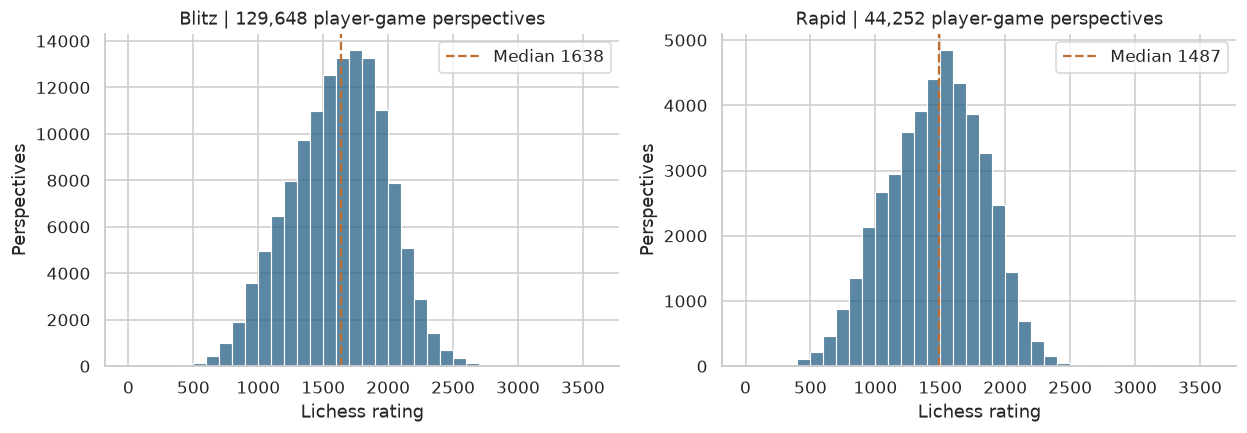

,count,median,mean,std,min,max
speed,,,,,,
blitz,129648,"1,638.000","1,615.856",366.344,400,3055
rapid,44252,"1,487.000","1,465.392",367.179,400,3066


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1), sharex=True)
for ax, speed in zip(axes, ["blitz", "rapid"]):
    sub = perspectives[perspectives.speed.eq(speed)]
    sns.histplot(data=sub, x="player_rating", bins=np.arange(0, 3601, 100), ax=ax, color="#255F85")
    ax.axvline(sub.player_rating.median(), color="#BF6F32", linestyle="--", label=f"Median {sub.player_rating.median():.0f}")
    ax.set(title=f"{speed.title()} | {len(sub):,} player-game perspectives", xlabel="Lichess rating", ylabel="Perspectives")
    ax.legend()
fig.tight_layout(); save_figure("C1_01_rating_distribution.png")
display(perspectives.groupby("speed").player_rating.agg(["count", "median", "mean", "std", "min", "max"]))

## EDA 2 — opening exposure

Families are classified from the prefix. The displayed 12 families are chosen by
exposure count, not by the result. Frequencies identify common review material;
they do not establish which opening is best or easiest to learn.

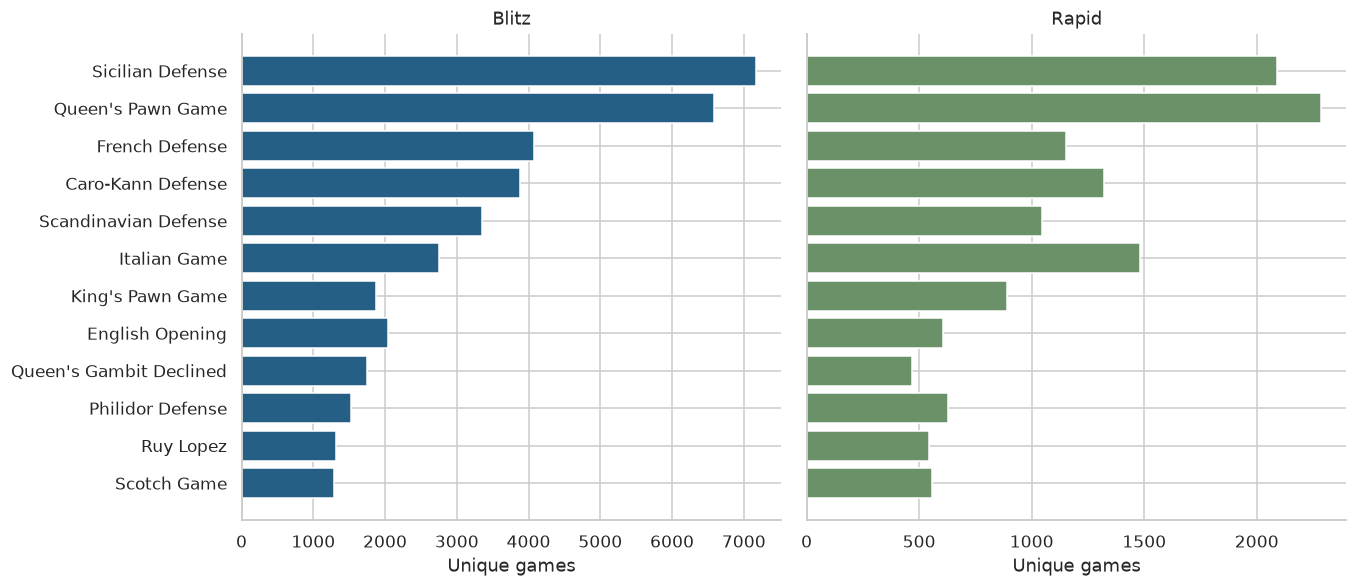

,speed,opening_family_20,games,share_pct
118,blitz,Sicilian Defense,7164,11.051
104,blitz,Queen's Pawn Game,6584,10.157
43,blitz,French Defense,4071,6.280
21,blitz,Caro-Kann Defense,3875,5.978
114,blitz,Scandinavian Defense,3350,5.168
56,blitz,Italian Game,2756,4.252
38,blitz,English Opening,2040,3.147
66,blitz,King's Pawn Game,1869,2.883
240,rapid,Queen's Pawn Game,2284,10.323
253,rapid,Sicilian Defense,2091,9.450


In [10]:
top_families = games.opening_family_20.value_counts().head(12).index.tolist()
exposure = games.groupby(["speed", "opening_family_20"], observed=True).size().rename("games").reset_index()
exposure["share_pct"] = 100*exposure.games / exposure.speed.map(games.speed.value_counts())
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.5), sharey=True)
for ax, speed in zip(axes, ["blitz", "rapid"]):
    values = exposure[exposure.speed.eq(speed)].set_index("opening_family_20").reindex(top_families).fillna(0)
    ax.barh(np.arange(len(top_families)), values.games, color="#255F85" if speed=="blitz" else "#6B9168")
    ax.set(yticks=np.arange(len(top_families)), yticklabels=top_families, xlabel="Unique games", title=speed.title())
axes[0].invert_yaxis(); fig.tight_layout(); save_figure("C1_02_opening_exposure.png")
display(exposure.sort_values(["speed", "games"], ascending=[True, False]).groupby("speed").head(8))
exposure.to_csv(TABLES / "C1_opening_exposure.csv", index=False)

## EDA 3 — rating differences and observed points

A rating difference is a plausible alternative explanation for an opening's score.
Bins below are descriptive, declared boundaries. The y-axis is White's points per game
including draws; it is not a calibrated probability of winning.

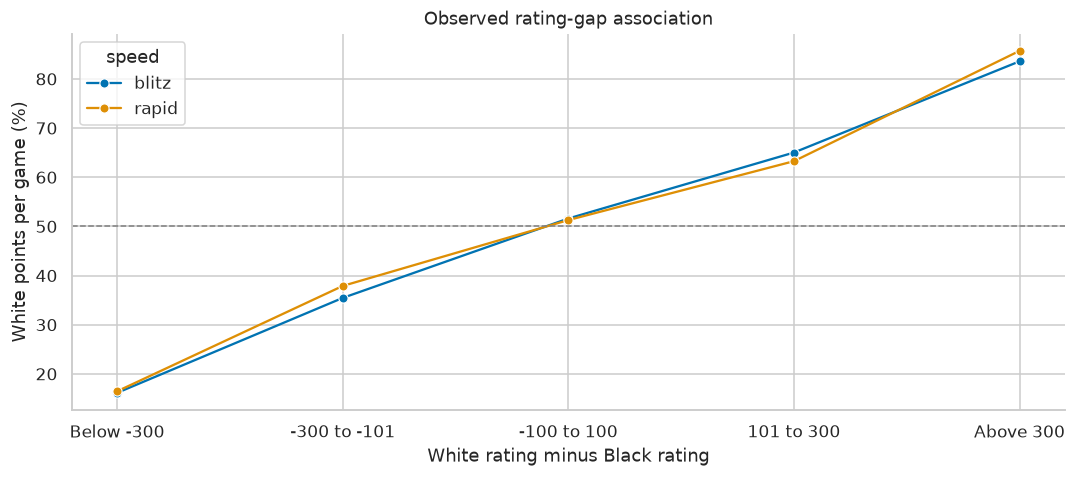

,speed,gap_band,games,score_pct
0,blitz,Below -300,1184,16.132
1,blitz,-300 to -101,3555,35.443
2,blitz,-100 to 100,55355,51.596
3,blitz,101 to 300,3583,65.015
4,blitz,Above 300,1147,83.566
5,rapid,Below -300,462,16.450
6,rapid,-300 to -101,1522,37.878
7,rapid,-100 to 100,18190,51.275
8,rapid,101 to 300,1501,63.258
9,rapid,Above 300,451,85.698


In [11]:
gap_edges = [-np.inf, -300, -100, 101, 301, np.inf]
gap_labels = ["Below -300", "-300 to -101", "-100 to 100", "101 to 300", "Above 300"]
relation = games.assign(gap_band=pd.cut(games.rating_gap, gap_edges, labels=gap_labels, right=False))
relation = relation.groupby(["speed", "gap_band"], observed=True).agg(games=("game_id", "size"), score_pct=("white_score", lambda x: 100*x.mean())).reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=relation, x="gap_band", y="score_pct", hue="speed", marker="o", errorbar=None, ax=ax)
ax.axhline(50, color="gray", linewidth=1, linestyle="--")
ax.set(xlabel="White rating minus Black rating", ylabel="White points per game (%)", title="Observed rating-gap association")
fig.tight_layout(); save_figure("C1_03_rating_gap_relationship.png")
display(relation)
relation.to_csv(TABLES / "C1_rating_gap_relationship.csv", index=False)

## EDA 4 — the KPI by color, level and speed

The complete table includes every observed cell. Displayed heatmap cells require at
least 50 games. Empty cells mean insufficient support, not zero performance.
Each label combines observed points (%) and its denominator. Cells across different
rating bands or colors answer different questions and should not be pooled into
a universal opening ranking. Differences remain observational and unadjusted.

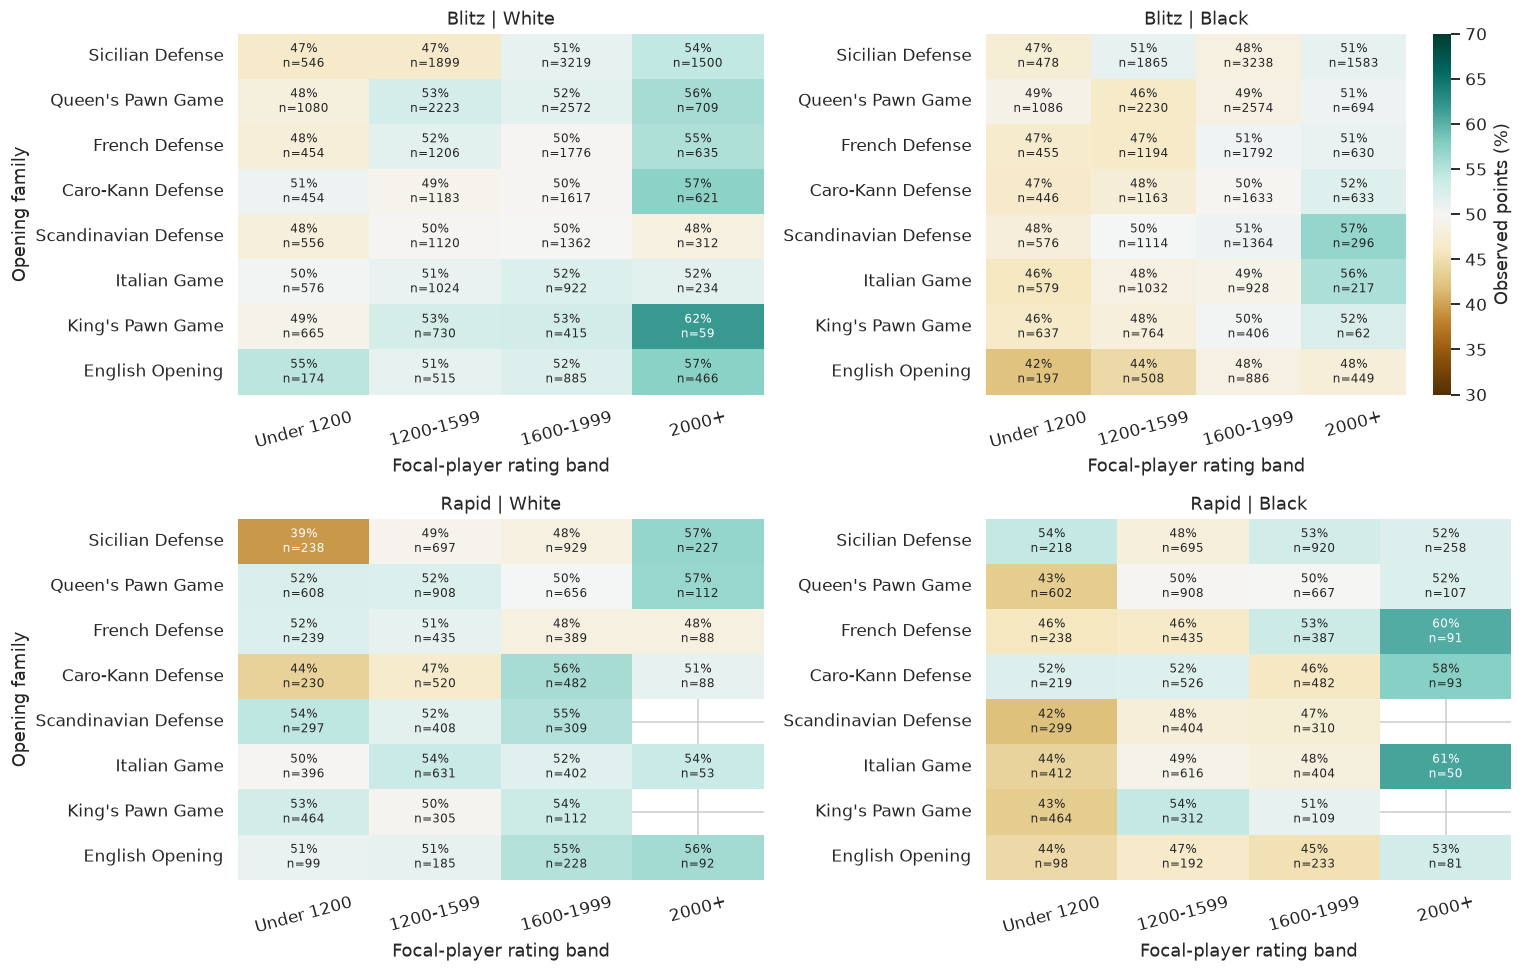

,speed,color,rating_band,opening_family_20,games,points,score_rate,mean_rating_gap,score_pct,display_eligible
359,blitz,black,1600-1999,Sicilian Defense,3238,"1,568.000",0.484,7.832,48.425,True
861,blitz,white,1600-1999,Sicilian Defense,3219,"1,648.000",0.512,-7.302,51.196,True
345,blitz,black,1600-1999,Queen's Pawn Game,2574,"1,248.500",0.485,8.979,48.504,True
848,blitz,white,1600-1999,Queen's Pawn Game,2572,"1,329.500",0.517,4.056,51.691,True
214,blitz,black,1200-1599,Queen's Pawn Game,2230,"1,036.000",0.465,-12.972,46.457,True
717,blitz,white,1200-1599,Queen's Pawn Game,2223,"1,171.000",0.527,-8.557,52.677,True
730,blitz,white,1200-1599,Sicilian Defense,1899,885.500,0.466,-30.464,46.630,True
227,blitz,black,1200-1599,Sicilian Defense,1865,954.000,0.512,-4.714,51.153,True
288,blitz,black,1600-1999,French Defense,1792,907.000,0.506,8.840,50.614,True
791,blitz,white,1600-1999,French Defense,1776,884.000,0.498,3.958,49.775,True


In [12]:
c1_kpis = kpi_table(perspectives)
c1_kpis.to_csv(TABLES / "C1_kpi_by_segment.csv", index=False)
top8 = top_families[:8]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (speed, color) in zip(axes.flat, [("blitz","white"),("blitz","black"),("rapid","white"),("rapid","black")]):
    sub = c1_kpis[(c1_kpis.speed.eq(speed)) & (c1_kpis.color.eq(color)) & c1_kpis.opening_family_20.isin(top8)]
    scores = sub.pivot(index="opening_family_20", columns="rating_band", values="score_pct").reindex(index=top8, columns=RATING_LABELS)
    counts = sub.pivot(index="opening_family_20", columns="rating_band", values="games").reindex(index=top8, columns=RATING_LABELS).fillna(0)
    labels = scores.copy().astype(object)
    for family in scores.index:
        for band in scores.columns:
            labels.loc[family,band] = f"{scores.loc[family,band]:.0f}%\nn={counts.loc[family,band]:.0f}" if counts.loc[family,band]>=MIN_CELL_GAMES else ""
    sns.heatmap(scores, mask=counts.lt(MIN_CELL_GAMES), annot=labels, fmt="", cmap="BrBG", vmin=30, vmax=70, center=50,
                cbar=ax is axes[0,1], ax=ax, annot_kws={"fontsize":8}, cbar_kws={"label":"Observed points (%)"})
    ax.set(title=f"{speed.title()} | {color.title()}", xlabel="Focal-player rating band", ylabel="Opening family" if ax in axes[:,0] else "")
    ax.tick_params(axis="x", rotation=15)
fig.tight_layout(); save_figure("C1_04_score_heatmaps.png")
display(c1_kpis[c1_kpis.display_eligible].sort_values("games", ascending=False).head(16))

## EDA 5 — missingness and diagnostic associations

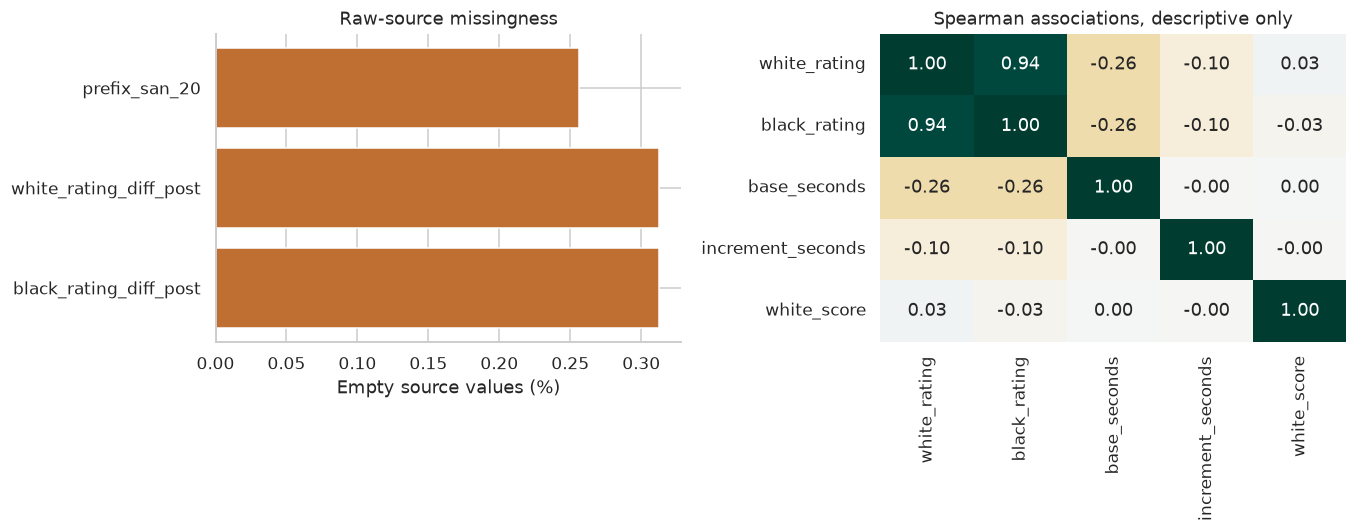

,empty_pct
black_rating_diff_post,0.313
white_rating_diff_post,0.313
prefix_san_20,0.256


,white_rating,black_rating,base_seconds,increment_seconds,white_score
white_rating,1.000,0.944,-0.263,-0.104,0.028
black_rating,0.944,1.000,-0.263,-0.105,-0.027
base_seconds,-0.263,-0.263,1.000,-0.002,0.000
increment_seconds,-0.104,-0.105,-0.002,1.000,-0.001
white_score,0.028,-0.027,0.000,-0.001,1.000


In [13]:
raw_missing = raw.eq("").mean().mul(100).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
show_missing = raw_missing[raw_missing.gt(0)]
if len(show_missing):
    axes[0].barh(show_missing.index, show_missing.values, color="#BF6F32")
    axes[0].set(xlabel="Empty source values (%)", title="Raw-source missingness")
else:
    axes[0].text(.5,.5,"No empty values in the reduced source",ha="center",transform=axes[0].transAxes)
    axes[0].set_axis_off()
corr = games[["white_rating","black_rating","base_seconds","increment_seconds","white_score"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="BrBG", vmin=-1, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Spearman associations, descriptive only")
fig.tight_layout(); save_figure("C1_05_missingness_correlations.png")
display(raw_missing[raw_missing.gt(0)].rename("empty_pct").to_frame())
display(corr)
corr.to_csv(TABLES / "C1_spearman.csv")

## Interpretation and bounded decision

In [14]:
# Exposure-led review agenda: choose by frequency, not by observed wins.
# The score accompanies each choice as context, never as a causal ranking.
agenda_keys=["speed","color","rating_band"]
agenda_candidates=c1_kpis[c1_kpis.display_eligible & c1_kpis.opening_family_20.ne("Unclassified")].copy()
c1_agenda=agenda_candidates.sort_values(agenda_keys+["games","opening_family_20"],ascending=[True,True,True,False,True]).groupby(agenda_keys,observed=True).head(1)
display(Markdown("**Provisional review agenda:** the most frequent supported family in each speed × color × focal-level cell. This prioritises relevance of examples, not opening superiority. The 50-game support rule is operational."))
display(c1_agenda[agenda_keys+["opening_family_20","games","score_pct"]])
c1_agenda.to_csv(TABLES/"C1_training_agenda.csv",index=False)
summary["training_agenda_cells"]=len(c1_agenda)
summary["spearman_gap_score"] = float(games[["rating_gap","white_score"]].corr(method="spearman").iloc[0,1])
summary["top_families"] = games.opening_family_20.value_counts().head(12).to_dict()
display(Markdown(f"""
**Observation.** The prepared cohort has **{summary['prepared_games']:,} unique games**
({summary['speed_counts'].get('blitz',0):,} blitz and {summary['speed_counts'].get('rapid',0):,} rapid).
The most frequent prefix family is **{summary['most_common_family']}**
({summary['most_common_family_games']:,} games). White's descriptive points rate is
**{summary['white_score_pct']:.2f}%**; draws are **{summary['draw_pct']:.2f}%** of games.

**Interpretation.** The Spearman association between White's rating gap and points is
**{summary['spearman_gap_score']:.3f}**. Opening scores must be interpreted alongside
opponent strength and color. This is an association in the observed cohort, not an
estimate of the causal effect of a rating difference or an opening choice.

**Recommendation.** Start review planning with frequently encountered, adequately
supported families within each level × speed × color cell. Inspect representative
games before assigning instructional content. A low observed score is a review signal,
not evidence of an intrinsically bad opening. Do not generalise these UTC windows to
the full platform or claim that a training intervention has been evaluated.
"""))
(ROOT / "outputs/C1_summary.json").write_text(json.dumps(summary, indent=2, default=int))

**Provisional review agenda:** the most frequent supported family in each speed × color × focal-level cell. This prioritises relevance of examples, not opening superiority. The 50-game support rule is operational.

,speed,color,rating_band,opening_family_20,games,score_pct
89,blitz,black,Under 1200,Queen's Pawn Game,1086,48.757
214,blitz,black,1200-1599,Queen's Pawn Game,2230,46.457
359,blitz,black,1600-1999,Sicilian Defense,3238,48.425
486,blitz,black,2000+,Sicilian Defense,1583,51.263
593,blitz,white,Under 1200,Queen's Pawn Game,1080,48.241
717,blitz,white,1200-1599,Queen's Pawn Game,2223,52.677
861,blitz,white,1600-1999,Sicilian Defense,3219,51.196
988,blitz,white,2000+,Sicilian Defense,1500,54.333
1086,rapid,black,Under 1200,Queen's Pawn Game,602,43.023
1202,rapid,black,1200-1599,Queen's Pawn Game,908,49.725



**Observation.** The prepared cohort has **86,950 unique games**
(64,824 blitz and 22,126 rapid).
The most frequent prefix family is **Sicilian Defense**
(9,255 games). White's descriptive points rate is
**51.31%**; draws are **4.42%** of games.

**Interpretation.** The Spearman association between White's rating gap and points is
**0.149**. Opening scores must be interpreted alongside
opponent strength and color. This is an association in the observed cohort, not an
estimate of the causal effect of a rating difference or an opening choice.

**Recommendation.** Start review planning with frequently encountered, adequately
supported families within each level × speed × color cell. Inspect representative
games before assigning instructional content. A low observed score is a review signal,
not evidence of an intrinsically bad opening. Do not generalise these UTC windows to
the full platform or claim that a training intervention has been evaluated.


2736

## Future ML and dashboard feasibility

A concrete future supervised task is **three-class game-result prediction**
(White win / draw / Black win) immediately after Black's 10th move. Inputs already
available are the two ratings, their difference, clock parameters, speed and the
prefix-derived opening family. Post-game rating changes, final opening tags, full
move count, result and termination are excluded from predictors. Training remains
outside C1; predictive performance is not promised.

The task supports evaluation of whether a simple information set adds useful
descriptive/predictive context; it does not optimise a player's opening choice or
measure instructional benefit. A dashboard would show exposure, points, denominators,
level, color, speed, source dates and coverage flags. It would help a proposed
coordinator choose material to review rather than merely display a gallery of charts.

## Limitations and alternatives

- The three short source windows create strong time-of-day and calendar coverage limits.
- Games ending before the checkpoint are absent from the analytical cohort. Conclusions concern games reaching the checkpoint, not every game starting with an opening.
- Repeated players and opponents make game outcomes dependent. No independent-observation confidence intervals or significance claims are made.
- Full-game opening tags and prefix labels can disagree through later moves, transpositions or taxonomy changes. They must not be interchanged silently.
- Grouping by a broad family can hide variation differences. A last matched family is not a full evaluation of the board or players' opening knowledge.
- Unadjusted points rates mix opponents of different strength within a level. W2 adds a declared close-rating descriptive check and an implemented validation design.
- Neither causal identification nor a finished dashboard is required here. Club training costs, learning outcomes and intervention assignments are not observed.

## Process record

### Decisions and checks

| Stage | Alternative | Decision and evidence |
|---|---|---|
| Topic selection | School-audit continuation, Valorant, chess | Team selected chess after public-data feasibility comparison. Previous school artifacts are preserved, not rewritten as chess work. |
| Scope | Timeout outcomes or openings; rapid only or both speeds | Team selected openings, multiple rating bands, blitz and rapid separately. |
| Source | Historical 2013–2017 convenience CSV or recent records | Official 2026 archive prefixes; extraction manifest and byte-range response verified. Narrow coverage disclosed. |
| Opening measurement | Final Opening header or observed position prefix | Position lookup restricted to 20 plies; legal prefixes, unknowns and cardinality audited. |
| KPI | Win percentage excluding draws or points including draws | Points per game with explicit denominator, color and level. Complementary score assertion prevents misleading combined-color ranking. |
| Display | Rank every cell or require basic support | A 50-game display threshold, without dropping small cells from stored tables or claiming statistical sufficiency. |

### Instructor feedback and response

No C1 feedback was supplied. The team stated that any eventual feedback would concern
the earlier topic. W2 uses explicitly labelled self-audits; no instructor comments or
approval of the topic change are fabricated.

### Individual contributions and reflection

Confirmed members: Javier Alcaíno, Lucas Riquelme and Renato Varela. The group selected
the scope through this conversation. Individual allocation, learning gains and unresolved
uncertainties have not been supplied and remain **to be confirmed by each member**.
This tracking version does not invent those statements. A worksheet is provided separately.

### AI use and verification

AI assisted source discovery, code, notebook explanations and report preparation.
The recorded prompt choices include openings instead of the suggested timeout topic,
both speeds instead of rapid only, and recent instead of historical data. Those choices
came from the user. Checks include official-source byte ranges and hashes, deterministic
prefix reconstruction, row accounting, lookup cardinality, color complementarity and
complete notebook execution. Code-assisted verification does not establish that the
members have already reviewed or can personally defend every result; that review is theirs.

## Sources and methodological references

1. [Lichess open database](https://database.lichess.org/#standard_games), official monthly standard-rated PGN archives, July–September 2026; retrieved 21 October 2026; CC0.
2. [Lichess opening names](https://github.com/lichess-org/chess-openings), commit recorded in `provenance/source_manifest.json`; CC0; position matching and family-name convention.
3. [Lichess FAQ](https://lichess.org/faq), speed estimated by base seconds + 40 × increment; blitz 180–479 seconds and rapid 480–1499 seconds.
4. [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), training-only fitting and leakage prevention.
5. Course C1 brief/rubric, W2 brief/rubric, Classes 01–04 and course calendar supplied with this project. Local originals are outside this package in the parent workspace; `provenance/course_sources.json` records filenames and checksums.

This is an educational observatory proposed by the team, not an evaluation commissioned
by Lichess or a real club. Statistical significance and predictive performance are not
claimed. Source code, reduced inputs and saved notebook outputs make calculations inspectable.